# Analysis of Patterned Optogenetic Stimulation (In Vitro)

This notebook demonstrates how to load, process, and perform spatial mapping of patch clamp data recorded during patterned optogenetic stimulation. 

Key steps include:
1.  Loading electrophysiology recordings from ABF files.
2.  Loading and processing the image patterns used for stimulation.
3.  Mapping the stimulation coordinates to the recording trials.
4.  Visualizing spatially organized response maps.

Methods used here rely on `xarray` for handling multidimensional data and metadata, ensuring that spatial coordinates and temporal info travel with the data.

In [1]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from mimo_pack.fileio.abf import load_abf
from mimo_pack.fileio.image import load_images
from mimo_pack.plot.map import wave_map
from mimo_pack.plot.invitro import focal_stim_map
from mimo_pack.preprocess.invitro import format_focal_stimulation

## Loading Recording Data

We start by loading the electrophysiological data using `load_abf`. This function reads Axon Binary Format (ABF) files and returns an `xarray.DataArray`. This data structure includes dimensions for time, channel, and epoch (sweep), along with essential metadata like sampling rate and channel units.

In [2]:
abf_path = os.path.join('..','test_data','invitro','25707017.abf')
rec = load_abf(abf_path)
print(rec)

<xarray.DataArray (time: 50000, channel: 4, epoch: 100)> Size: 160MB
array([[[-63.8123, -64.2395, -63.5986, ..., -65.3687, -64.3921,
         -63.9343],
        [  1.2207,   6.7139,   4.2725, ...,  -3.6621, -10.376 ,
          -9.7656],
        [ -0.0012,  -0.0024,  -0.0027, ...,  -0.0031,  -0.0018,
          -0.0018],
        [  0.0031,   0.0024,   0.0027, ...,   0.0031,   0.0031,
           0.0027]],

       [[-63.6902, -64.209 , -63.6902, ..., -65.7654, -64.3005,
         -63.9038],
        [  4.2725,   4.8828,   2.4414, ..., -12.8174,  -9.7656,
          -7.9346],
        [ -0.0018,  -0.0024,  -0.0021, ...,  -0.0018,  -0.0021,
          -0.0021],
        [  0.0027,   0.0027,   0.0021, ...,   0.0015,   0.0027,
           0.0027]],

       [[-63.6902, -64.6057, -63.9954, ..., -65.3992, -64.3005,
         -63.8428],
...
        [  0.0021,   0.0027,   0.0031, ...,   0.0027,   0.0031,
           0.0027]],

       [[-64.27  , -64.0564, -64.6973, ..., -64.27  , -63.9954,
         -64.2395

## Loading Stimulation Patterns

Next, we load the sequence of image masks used for focal optogenetic stimulation. The `load_images` function reads all images from a directory and stacks them into a single `DataArray`. The `insert_blank=True` argument ensures that a blank pattern is included if the protocol involves non-stimulation trials or requires zero-indexing alignment.

In [3]:
imgs_path = os.path.join('..','test_data','invitro','single_squares')
patterns = load_images(imgs_path, insert_blank=True)
print(patterns)

<xarray.DataArray (image: 50, y: 500, x: 835)> Size: 21MB
array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
...
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
       

## Visualizing Stimulation Patterns

To understand the spatial arrangement of the stimuli, we can visualize the aggregate of all projected patterns. The code below assigns a unique index to each pattern and sums them to create a composite map, showing the grid or layout of the stimulation spots relative to the field of view.

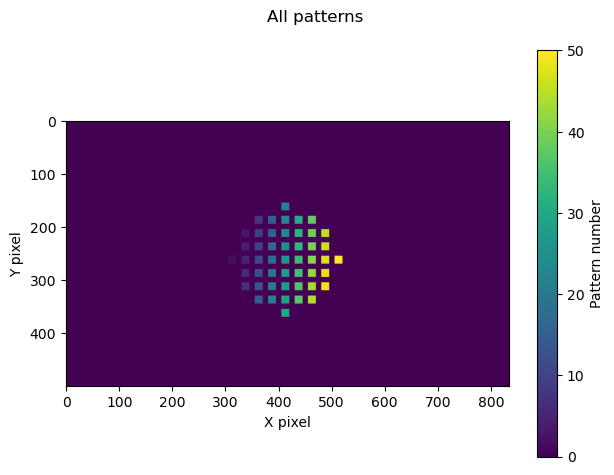

In [4]:
# gives each pattern a unique number
patterns_uniq = (patterns>0) * (np.arange(len(patterns))[:, None, None]+1)

# collapse all patterns for plotting
patterns_sum = patterns_uniq.sum(dim='image').to_numpy()

fig = plt.figure()
plt.imshow(patterns_sum, aspect='equal')
fig.suptitle('All patterns')
cbar = plt.colorbar()
cbar.set_label('Pattern number')
plt.xlabel('X pixel')
plt.ylabel('Y pixel')
fig.tight_layout()


## Computing Stimulation Coordinates

To map the physiological responses to physical space, we need to reduce each image pattern to a coordinate (centroid). We calculate the center of mass for each pattern in the stack. This provides us with distinct (x, y) coordinates for every stimulation condition.

In [5]:
# for each image in imgs_xr, identify the x,y location of the center of mass. If no pixels are above 0, then return np.nan
def center_of_mass(image: np.ndarray) -> np.ndarray:
    """Calculate the center of mass of a 2D image."""
    if np.all(image == 0):
        return np.array([np.nan, np.nan])  # No pixels above 0

    y_indices, x_indices = np.indices(image.shape)
    total_mass = np.sum(image)

    if total_mass == 0:
        return np.array([np.nan, np.nan])  # Avoid division by zero

    y_center = np.sum(y_indices * image) / total_mass
    x_center = np.sum(x_indices * image) / total_mass

    return np.array([y_center, x_center])

# Apply the center_of_mass function to each image in the DataArray
centers = xr.apply_ufunc(
    center_of_mass,
    patterns,
    input_core_dims=[["y", "x"]],
    output_core_dims=[["center"]],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float],
)

# Assign coordinate names to the center dimension
centers = centers.assign_coords(center=["y", "x"])
print(centers)

<xarray.DataArray (image: 50, center: 2)> Size: 800B
array([[ nan,  nan],
       [262., 312.],
       [212., 337.],
       ...,
       [287., 487.],
       [312., 487.],
       [262., 512.]], shape=(50, 2))
Coordinates:
  * image       (image) int64 400B 0 1 2 3 4 5 6 7 8 ... 42 43 44 45 46 47 48 49
    image_name  (image) <U21 4kB 'blank' ... 'single_square_049.bmp'
  * center      (center) <U1 8B 'y' 'x'


## Aligning Stimulation Coordinates with Recording Trials

The recording generally consists of multiple trials (sweeps), where each trial corresponds to a specific stimulation pattern played in a defined sequence. We use the protocol information stored in the recording's attributes to map the computed (x, y) coordinates to the corresponding epochs in the physiological data. This adds `stim_x` and `stim_y` as coordinates along the `epoch` axis to the `rec` DataArray.

In [6]:
print('Our recording protocol was {}'.format(rec.attrs['protocol']))

# Extract the centers of mass for each pattern
stim_cents = centers.data

# add coordinate for stim_cents to iv
rec.coords['stim_x'] = ('epoch', np.tile(stim_cents[:,0],2))
rec.coords['stim_y'] = ('epoch', np.tile(stim_cents[:,1],2))

Our recording protocol was Left_StaticSeqLong_SingleCircle


## Spatial Mapped Visualization

With the `stim_x` and `stim_y` coordinates attached to our data, we can use `wave_map` to visualize the postsynaptic responses plotted at their virtual physical locations. This provides an intuitive map of the cell's receptive field to the optogenetic stimulation.

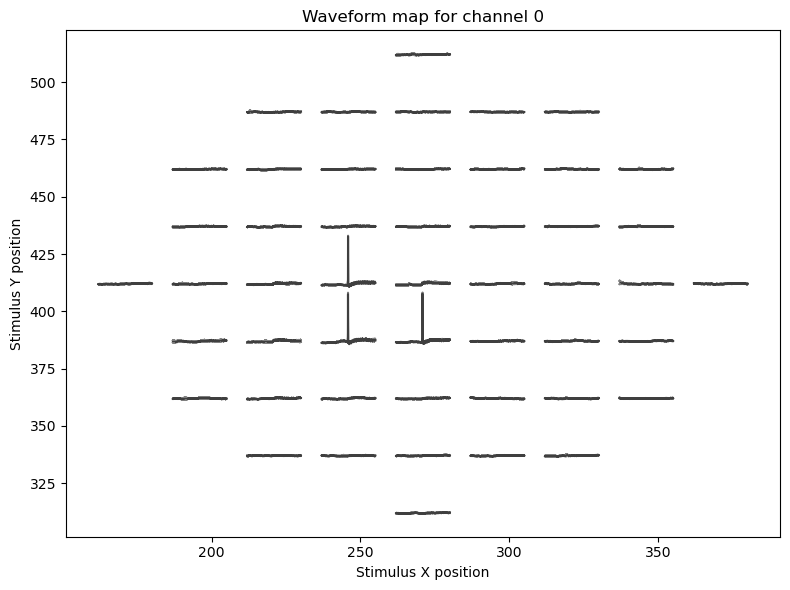

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
rec_plot = rec.sel(channel=0, time=slice(0.9, 1.2))
rec_plot = rec_plot - rec_plot.mean(dim='time')  # remove DC offset
wave_map(rec_plot, x_coord='stim_x', y_coord='stim_y',
            x_scale=0.003, y_scale=.2, ax=ax, alpha=0.5)
ax.set_title('Waveform map for channel 0')
ax.set_xlabel('Stimulus X position')
ax.set_ylabel('Stimulus Y position')
fig.tight_layout()

## Streamlined Analysis with Helper Functions

The steps above—loading, center-of-mass calculation, and coordinate assignment—are common for this type of experiment. The `mimo_pack` library provides high-level helper functions to automate this workflow.

- `format_focal_stimulation`: Takes the raw recording and image stack, computes centroids, and attaches coordinates.
- `focal_stim_map`: Automatically generates the spatial waveform map.

<Axes: title={'center': 'Waveform map for channel 0'}, xlabel='Stimulus X position', ylabel='Stimulus Y position'>

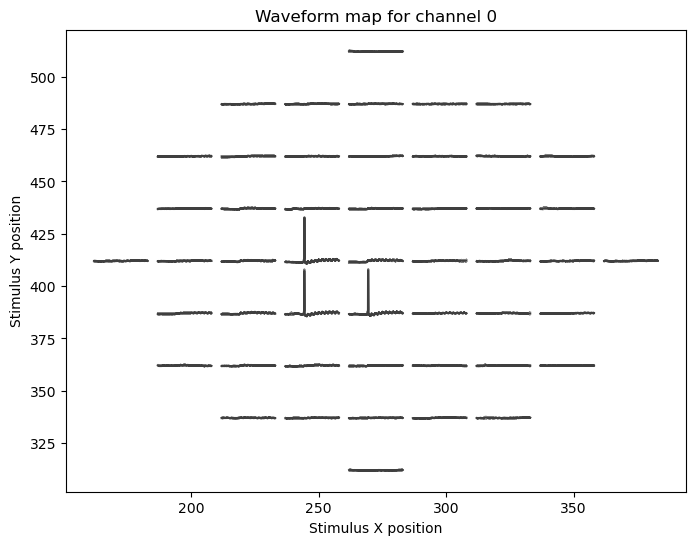

In [8]:
# Create file paths
imgs_path = os.path.join('..','test_data','invitro','single_squares')
abf_path = os.path.join('..','test_data','invitro','25707017.abf')

# Load the recording and patterns
rec = load_abf(abf_path)
patterns = load_images(imgs_path, insert_blank=True)

# Add stimulation locations to the recording
rec = format_focal_stimulation(rec, patterns)

fig, ax = plt.subplots(figsize=(8, 6))
focal_stim_map(rec, ax=ax, x_scale=0.007)